# NHANES 2005–2018 — Cohort Selection & Class Distribution

This notebook counts the analytical cohort stage by stage from the raw DEMO / DPQ files, checks the counts against the final feature table, and draws the **Data Description and Characteristics** figures. All counts are **unweighted**. It does not modify source data or rerun the preprocessing pipeline.

**Inputs** (same locations as the pipeline, see `nhanes/paths.py`):
- `$NHANES_DATA/<cycle>/DEMO_*.xpt`, `DPQ_*.xpt`: raw NHANES files
- `$NHANES_WORK/features/features_2005_2018.csv.gz`: final feature table

**Outputs** (in `$NHANES_WORK/data_analysis/`): `cohort_selection.csv`, `cycle_statistics.csv`, and `figures/01–03_*.png`.

**How to run:** set `NHANES_DATA` / `NHANES_WORK` the same way as for `run_pipeline.sh` (defaults: `./data`, `./outputs`) before starting Jupyter, then **Run All**. Run it from the repository root or from `data_analysis/`.

**Definitions:** adults aged ≥20, complete nine PHQ-9 answers, exclude participants identified as pregnant (`RIDEXPRG == 1`), depression label = PHQ-9 ≥10. Missing pregnancy codes are retained by the original pipeline. These are **sample proportions, not survey-weighted US population prevalence estimates**.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the repository root (the folder that holds nhanes/paths.py) from the project root or data_analysis/.
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'nhanes' / 'paths.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Cannot find nhanes/paths.py; run this notebook from the repository root or data_analysis/.')
sys.path.insert(0, str(ROOT))

from nhanes import io as nio  # noqa: E402
from nhanes.paths import WORK  # noqa: E402

FEATURES = WORK / 'features' / 'features_2005_2018.csv.gz'
OUT = WORK / 'data_analysis'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

CYCLES = nio.CYCLES_2005_2018                                   # '2005-2006', ...
SHORT = {c: c[:4] + '-' + c[-2:] for c in CYCLES}               # '2005-06', as in the feature table

## Cohort selection by cycle

Sequential counts from the raw files, using the same rules as `pipeline/step5_missing.ipynb`: age ≥ 20 → all nine PHQ-9 items valid after removing 7 / 9 (refused / don't know) → not identified as pregnant. The final counts must equal the rows of the feature table in every cycle.

In [2]:
rows = []
for cycle in CYCLES:
    demo = nio.read_component('DEMO', cycle, ['RIDAGEYR', 'RIDEXPRG'])
    dpq = nio.read_component('DPQ', cycle, nio.PHQ_ITEMS)
    if demo['SEQN'].duplicated().any() or dpq['SEQN'].duplicated().any():
        raise ValueError(f'Duplicate SEQN in {cycle}')

    age_ok = demo['RIDAGEYR'] >= 20
    items = dpq[nio.PHQ_ITEMS].apply(lambda col: nio.clean_codes(col, [7, 9]))
    complete_phq_ids = set(dpq.loc[items.notna().all(axis=1), 'SEQN'])
    phq_ok = demo['SEQN'].isin(complete_phq_ids)
    not_pregnant = demo['RIDEXPRG'] != 1      # pipeline rule: missing / other codes are kept

    age_n = int(age_ok.sum())
    phq_n = int((age_ok & phq_ok).sum())
    final_n = int((age_ok & phq_ok & not_pregnant).sum())
    rows.append({
        'cycle': SHORT[cycle],
        'All_DEMO': len(demo),
        'Age_20_plus': age_n,
        'Age_20_plus_Valid_PHQ9': phq_n,
        'Final_NonPregnant': final_n,
        'Excluded_Under20_or_AgeMissing': len(demo) - age_n,
        'Excluded_PHQ9_after_age': age_n - phq_n,
        'Excluded_Pregnant_after_PHQ9': phq_n - final_n,
    })
cohort = pd.DataFrame(rows)

frame = pd.read_csv(FEATURES, usecols=['cycle', 'depression'])
table_n = frame.groupby('cycle').size()
for r in cohort.itertuples(index=False):
    if int(table_n.get(r.cycle, -1)) != r.Final_NonPregnant:
        raise ValueError(f'{r.cycle}: raw cohort {r.Final_NonPregnant} != feature table {int(table_n.get(r.cycle, -1))}')

total = {'cycle': 'Overall', **{c: int(cohort[c].sum()) for c in cohort.columns.drop('cycle')}}
pd.concat([cohort, pd.DataFrame([total])], ignore_index=True).to_csv(OUT / 'cohort_selection.csv', index=False)
print(f'Verified: final cohort matches the feature table in every cycle, N = {len(frame):,}')
display(pd.concat([cohort, pd.DataFrame([total])], ignore_index=True))

Verified: final cohort matches the feature table in every cycle, N = 33,498


,cycle,All_DEMO,Age_20_plus,Age_20_plus_Valid_PHQ9,Final_NonPregnant,Excluded_Under20_or_AgeMissing,Excluded_PHQ9_after_age,Excluded_Pregnant_after_PHQ9
0,2005-06,10348,4979,4284,3975,5369,695,309
1,2007-08,10149,5935,5157,5104,4214,778,53
2,2009-10,10537,6218,5281,5222,4319,937,59
3,2011-12,9756,5560,4639,4594,4196,921,45
4,2013-14,10175,5769,5054,4995,4406,715,59
5,2015-16,9971,5719,4888,4829,4252,831,59
6,2017-18,9254,5569,4825,4779,3685,744,46
7,Overall,70190,39749,34128,33498,30441,5621,630


## Class distribution by cycle

In [3]:
assert frame['depression'].notna().all(), 'Missing target labels'
assert frame['depression'].isin([0, 1]).all(), 'Invalid target labels'

cycle = (frame.groupby('cycle', sort=True)['depression']
         .agg(Total='count', Depression='sum').reset_index())
cycle['Depression'] = cycle['Depression'].astype(int)
cycle['Non_Depression'] = cycle['Total'] - cycle['Depression']
cycle['Depression_Rate'] = (cycle['Depression'] / cycle['Total'] * 100).round(2)
cycle = cycle.set_index('cycle').loc[list(SHORT.values())].reset_index()

N = int(cycle['Total'].sum())
P = int(cycle['Depression'].sum())
Q = int(cycle['Non_Depression'].sum())
overall = pd.DataFrame([{'cycle': 'Overall', 'Total': N, 'Depression': P,
                         'Non_Depression': Q, 'Depression_Rate': round(P / N * 100, 2)}])
pd.concat([cycle, overall], ignore_index=True).to_csv(OUT / 'cycle_statistics.csv', index=False)

assert (cycle['Total'].to_numpy() == cohort['Final_NonPregnant'].to_numpy()).all()
print(f'Final cohort: {N:,} | Depression: {P:,} ({P/N:.2%}) | Non-depression: {Q:,} ({Q/N:.2%})')
display(pd.concat([cycle, overall], ignore_index=True))

Final cohort: 33,498 | Depression: 2,970 (8.87%) | Non-depression: 30,528 (91.13%)


,cycle,Total,Depression,Non_Depression,Depression_Rate
0,2005-06,3975,245,3730,6.16
1,2007-08,5104,498,4606,9.76
2,2009-10,5222,497,4725,9.52
3,2011-12,4594,420,4174,9.14
4,2013-14,4995,482,4513,9.65
5,2015-16,4829,393,4436,8.14
6,2017-18,4779,435,4344,9.10
7,Overall,33498,2970,30528,8.87


## Figure 1 — Overall cohort selection

Counts are sequential. The pregnancy step excludes only participants explicitly identified as pregnant, matching the project code.

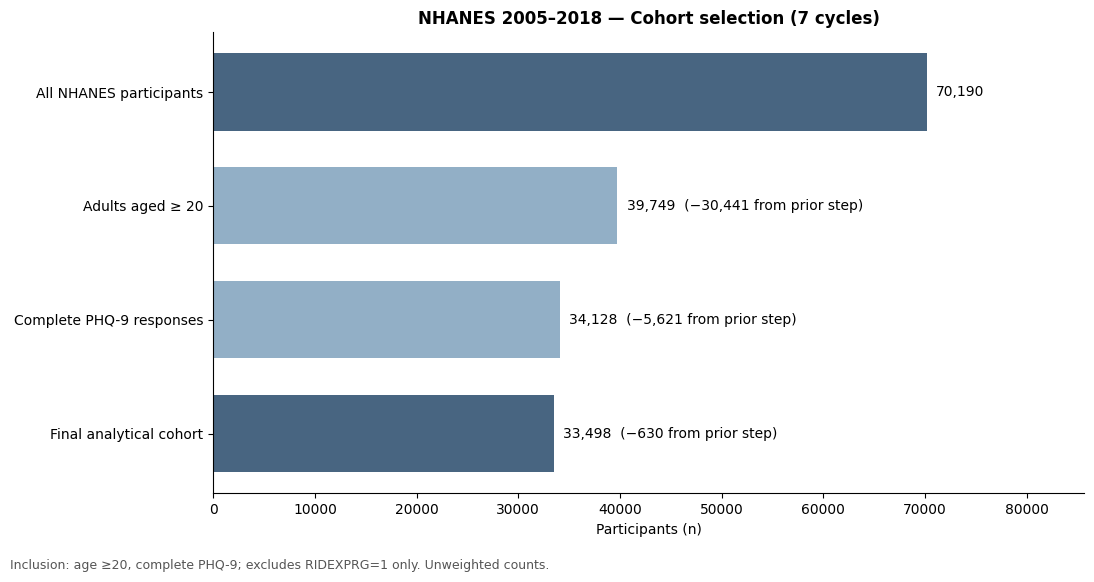

In [4]:
stages = ['All NHANES participants', 'Adults aged ≥ 20', 'Complete PHQ-9 responses', 'Final analytical cohort']
vals = [int(cohort[k].sum()) for k in ['All_DEMO', 'Age_20_plus', 'Age_20_plus_Valid_PHQ9', 'Final_NonPregnant']]
assert vals == [70190, 39749, 34128, 33498], 'Counts differ from the previously checked cohort; review source files.'
fig, ax = plt.subplots(figsize=(11, 5.8))
y = np.arange(len(vals))
ax.barh(y, vals, color=['#486581', '#92afc6', '#92afc6', '#486581'], height=.68)
ax.set_yticks(y, stages)
ax.invert_yaxis()
ax.set_xlabel('Participants (n)')
ax.set_title('NHANES 2005–2018 — Cohort selection (7 cycles)', weight='bold')
ax.set_xlim(0, max(vals) * 1.22)
for i, v in enumerate(vals):
    excluded = f'  (−{vals[i-1]-v:,} from prior step)' if i else ''
    ax.text(v + 900, i, f'{v:,}' + excluded, va='center', fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
fig.text(.01, .01, 'Inclusion: age ≥20, complete PHQ-9; excludes RIDEXPRG=1 only. Unweighted counts.', fontsize=9, color='#555555')
fig.tight_layout(rect=[0, .04, 1, 1])
fig.savefig(FIG / '01_cohort_selection.png', dpi=220, bbox_inches='tight')
plt.show()

## Figure 2 — Overall class distribution

The positive class is `PHQ-9 ≥ 10`. The 8.87% below is **not** a survey-weighted prevalence estimate.

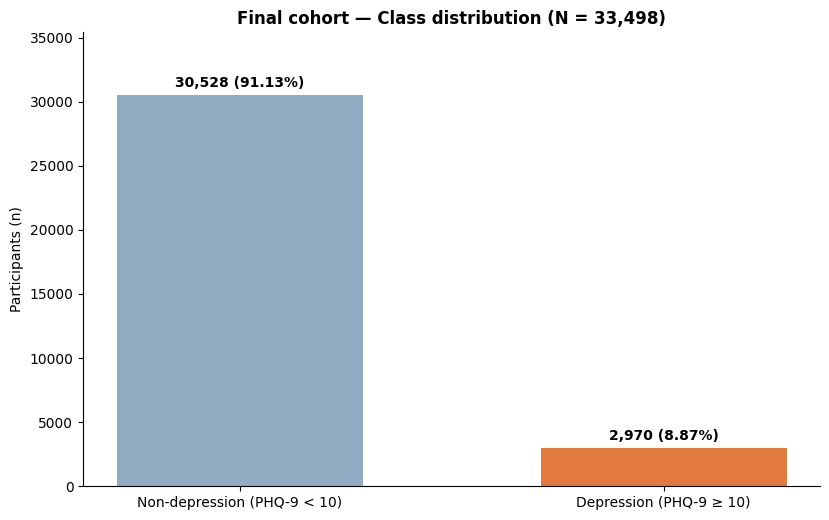

In [5]:
fig, ax = plt.subplots(figsize=(8.4, 5.3))
labels = ['Non-depression (PHQ-9 < 10)', 'Depression (PHQ-9 ≥ 10)']
counts = [Q, P]
bars = ax.bar(labels, counts, color=['#91abc3', '#e37a3d'], width=.58)
for bar, count in zip(bars, counts):
    ax.annotate(f'{count:,} ({count/N:.2%})', (bar.get_x() + bar.get_width() / 2, count),
                xytext=(0, 6), textcoords='offset points', ha='center', fontweight='bold')
ax.set_ylim(0, max(counts) * 1.16)
ax.set_ylabel('Participants (n)')
ax.set_title(f'Final cohort — Class distribution (N = {N:,})', weight='bold')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / '02_overall_class_distribution.png', dpi=220, bbox_inches='tight')
plt.show()

## Figure 3 — Class counts by cycle

How many negative and positive samples each LOCO test cycle has.

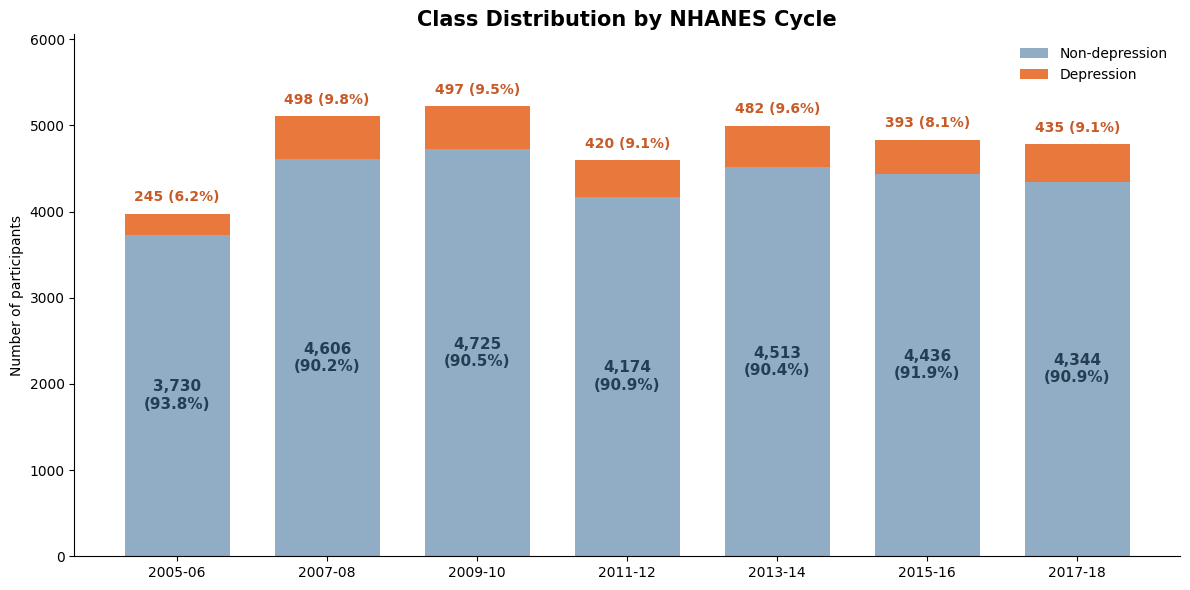

In [6]:
non_dep = cycle['Non_Depression'].astype(int).to_numpy()
dep = cycle['Depression'].astype(int).to_numpy()
total_n = non_dep + dep
non_dep_pct = non_dep / total_n * 100
dep_pct = dep / total_n * 100
x = np.arange(len(cycle))

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x, non_dep, color='#91ACC5', width=0.7, label='Non-depression')
ax.bar(x, dep, bottom=non_dep, color='#E9783D', width=0.7, label='Depression')
for i in range(len(cycle)):
    ax.text(x[i], non_dep[i] / 2, f'{non_dep[i]:,}\n({non_dep_pct[i]:.1f}%)',
            ha='center', va='center', fontsize=11, fontweight='bold', color='#243D53')
    ax.annotate(f'{dep[i]:,} ({dep_pct[i]:.1f}%)', xy=(x[i], total_n[i]), xytext=(0, 7),
                textcoords='offset points', ha='center', va='bottom', fontsize=10,
                fontweight='bold', color='#C75A27', annotation_clip=False)
ax.set_xticks(x)
ax.set_xticklabels(cycle['cycle'])
ax.set_ylabel('Number of participants')
ax.set_title('Class Distribution by NHANES Cycle', fontsize=15, fontweight='bold')
ax.set_ylim(0, max(total_n) * 1.16)
ax.legend(frameon=False, loc='upper right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
fig.savefig(FIG / '03_cycle_class_counts.png', dpi=300, bbox_inches='tight')
plt.show()

## Slide-ready takeaways

- **Data source:** NHANES 2005–2018, seven two-year cycles.
- **Cohort selection:** 70,190 participants → 39,749 aged ≥20 → 34,128 with complete PHQ-9 → **33,498** after excluding identified pregnant participants.
- **Class distribution:** 2,970 positive (8.87%); 30,528 negative (91.13%). This is an **imbalanced classification dataset**.
- **Across-cycle positive rates:** 6.16% (2005–06) to 9.76% (2007–08), calculated **without survey weights**.
- **Evaluation:** the project uses Leave-One-Cycle-Out rather than a single 80/20 train/test split.

All figures are also saved in `$NHANES_WORK/data_analysis/figures/`.